In [1]:
from itertools import batched
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import torch
from pgvector.sqlalchemy import Vector
from PIL import Image
from sentence_transformers import SentenceTransformer
from sqlalchemy import String, create_engine, select
from sqlalchemy.engine import URL
from sqlalchemy.orm import DeclarativeBase, Mapped, Session, mapped_column
from tqdm.notebook import tqdm

W1101 23:00:44.479000 82744 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


In [2]:
IMAGES_DIR = Path("data/images/small")

df = pd.read_csv("data/images/metadata/images.csv.gz")
df = df[(df["width"] >= 1000) & (df["height"] >= 1000)]
image_paths = [str(IMAGES_DIR / p) for p in df["path"] if (IMAGES_DIR / p).exists()]
len(image_paths)

342878

In [3]:
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
model = SentenceTransformer("clip-ViT-B-32", device=device)
model

modules.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/1.91k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.03k [00:00<?, ?B/s]

0_CLIPModel/model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

0_CLIPModel/model.safetensors: downloading bytes:           |  0.00B            

... (3 outputs left out)

vocab.json:   0%|          | 0.00/961k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

SentenceTransformer(
  (0): Transformer({'transformer_task': 'feature-extraction', 'modality_config': {'text': {'method': 'get_text_features', 'method_output_name': 'pooler_output'}, 'image': {'method': 'get_image_features', 'method_output_name': 'pooler_output'}}, 'module_output_name': 'sentence_embedding', 'architecture': 'CLIPModel'})
)

In [4]:
print("text embedding:", model.encode("a photo of a chair").shape)
print("image embedding:", model.encode(Image.open(image_paths[0])).shape)

text embedding: (512,)
image embedding: (512,)


In [5]:
vision = model[0].auto_model.config.vision_config
print("patch size:", vision.patch_size)
print("hidden size:", vision.hidden_size, "| layers:", vision.num_hidden_layers, "| heads:", vision.num_attention_heads)

patch size: 32
hidden size: 768 | layers: 12 | heads: 12


What is the vector size produced by clip-ViT-B-32?

> 512

What do ViT, B and 32 mean in the model name?

- `ViT` - Vision Transformer, the image encoder architecture
- `B` - Base model size (hidden size 768, 12 layers, 12 attention heads)
- `32` - patch size: the image is split into 32 x 32 pixel patches

In [6]:
db_url = URL.create(
    drivername="postgresql+psycopg",
    username="postgres",
    password="password",
    host="localhost",
    port=5555,
    database="similarity_search_service_db",
)
engine = create_engine(db_url)


class Base(DeclarativeBase):
    pass


class Img(Base):
    __tablename__ = "images"
    __table_args__ = {"extend_existing": True}

    VECTOR_LENGTH: int = 512

    id: Mapped[int] = mapped_column(primary_key=True)
    image_path: Mapped[str] = mapped_column(String(256))
    embedding: Mapped[list[float]] = mapped_column(Vector(VECTOR_LENGTH))


Base.metadata.create_all(engine)

In [7]:
MAX_IMAGES = 1_000
BATCH_SIZE = joblib.cpu_count(only_physical_cores=True)


def insert_images(engine, images):
    with Session(engine) as session:
        session.add_all(images)
        session.commit()


def vectorize_images(engine, model, image_paths):
    with tqdm(total=MAX_IMAGES) as pbar:
        for images_paths_batch in batched(image_paths[:MAX_IMAGES], BATCH_SIZE):
            images = [Image.open(path) for path in images_paths_batch]
            embeddings = model.encode(images)
            imgs = [Img(image_path=path, embedding=emb) for path, emb in zip(images_paths_batch, embeddings)]
            insert_images(engine, imgs)
            pbar.update(len(imgs))


vectorize_images(engine, model, image_paths)

  0%|          | 0/1000 [00:00<?, ?it/s]

In [8]:
class ImageSearch:
    def __init__(self, engine, model):
        self.engine = engine
        self.model = model

    def __call__(self, image_description: str, k: int):
        found_images = self.find_similar_images(image_description, k)
        self.display_images(found_images)

    def find_similar_images(self, image_description: str, k: int):
        image_embedding = self.model.encode(image_description)
        query = select(Img.image_path).order_by(Img.embedding.cosine_distance(image_embedding)).limit(k)
        with Session(self.engine) as session:
            return session.scalars(query).all()

    def display_images(self, images):
        fig, axes = plt.subplots(1, len(images), figsize=(15, 5))

        for i, img_path in enumerate(images):
            img = Image.open(img_path).convert("RGB")
            axes[i].imshow(img)
            axes[i].axis("off")
            axes[i].set_title(f"Image {i+1}")

        plt.show()


search = ImageSearch(engine, model)
queries = ["red shoes", "wooden table", "blue sofa", "phone case with flowers"]

  0%|          | 0/1000 [00:00<?, ?it/s]

MAX_IMAGES=1000, query: red shoes


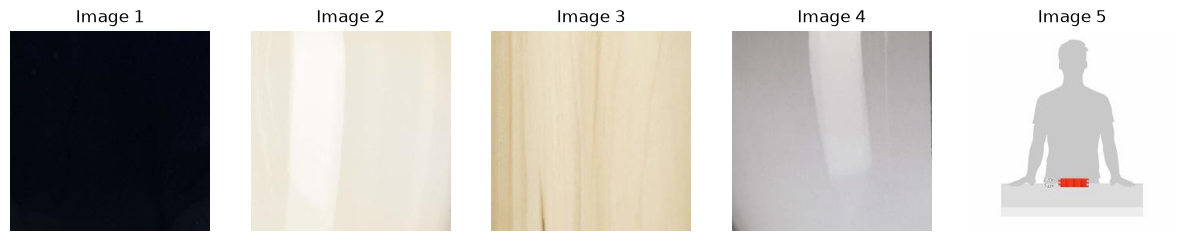

MAX_IMAGES=1000, query: wooden table


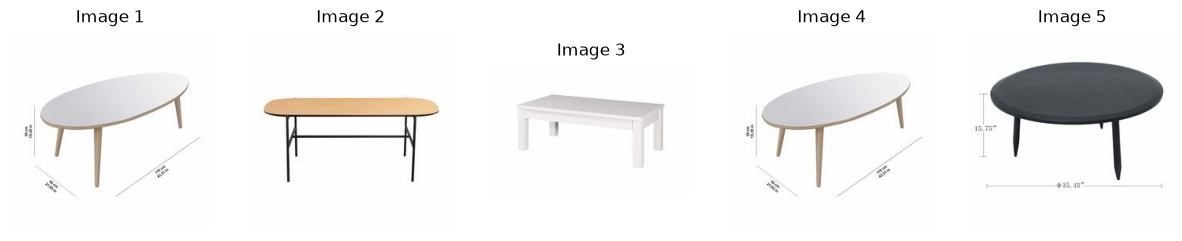

MAX_IMAGES=1000, query: blue sofa


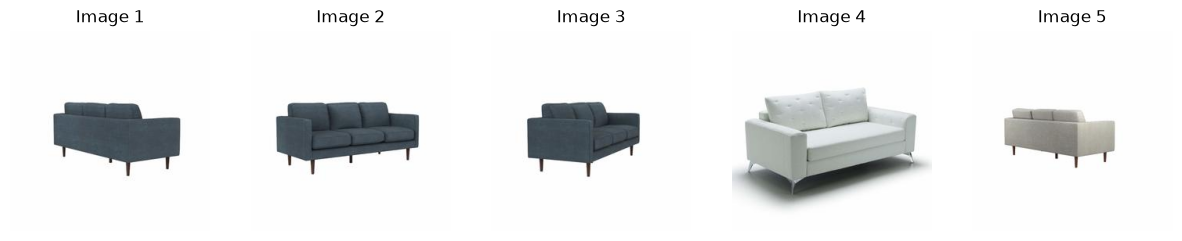

MAX_IMAGES=1000, query: phone case with flowers


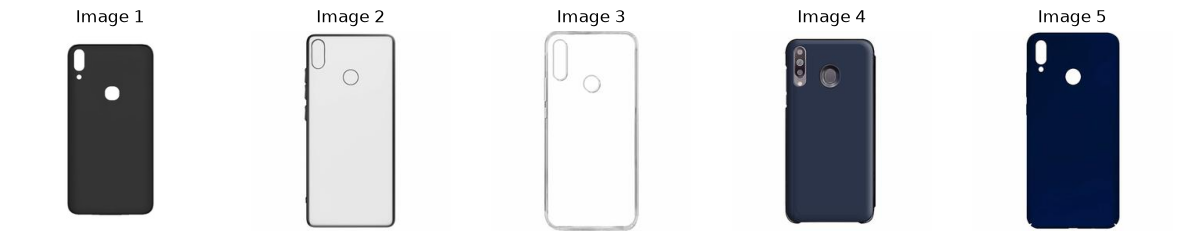

  0%|          | 0/10000 [00:00<?, ?it/s]

MAX_IMAGES=10000, query: red shoes


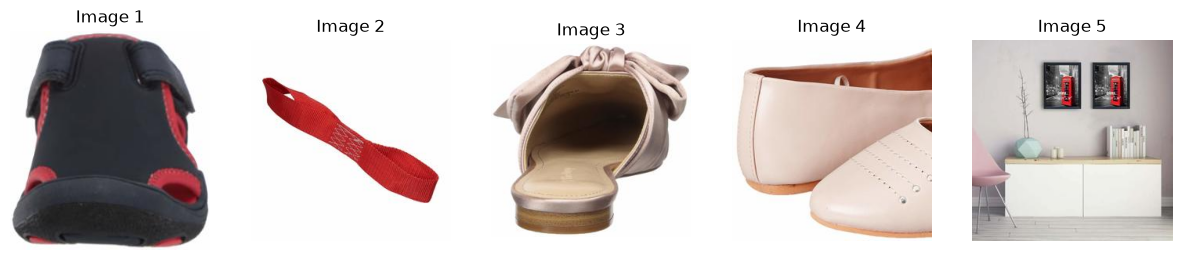

MAX_IMAGES=10000, query: wooden table


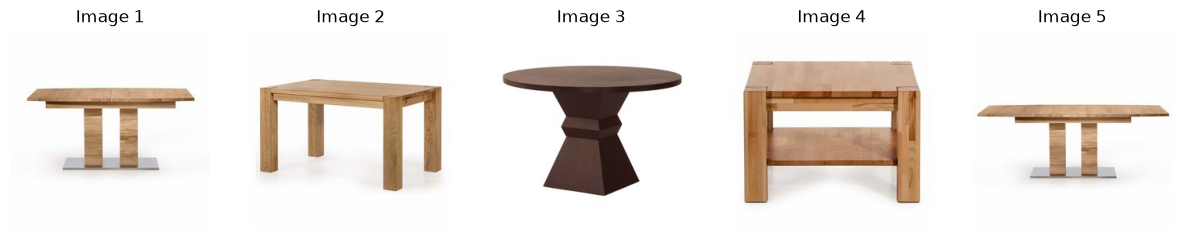

MAX_IMAGES=10000, query: blue sofa


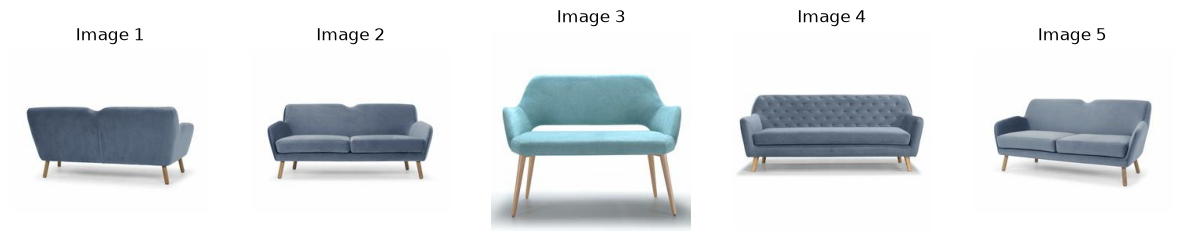

MAX_IMAGES=10000, query: phone case with flowers


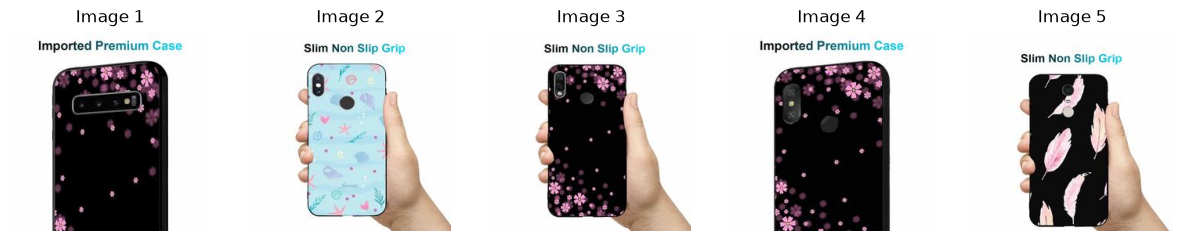

  0%|          | 0/50000 [00:00<?, ?it/s]

MAX_IMAGES=50000, query: red shoes


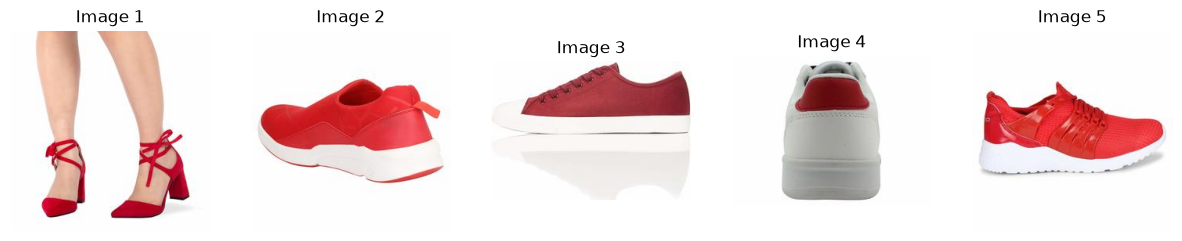

MAX_IMAGES=50000, query: wooden table


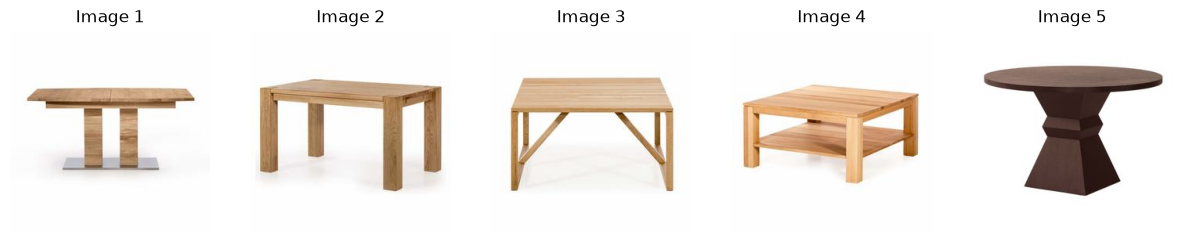

MAX_IMAGES=50000, query: blue sofa


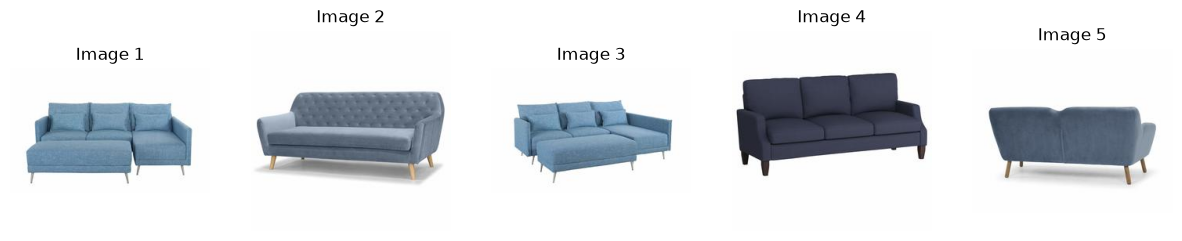

MAX_IMAGES=50000, query: phone case with flowers


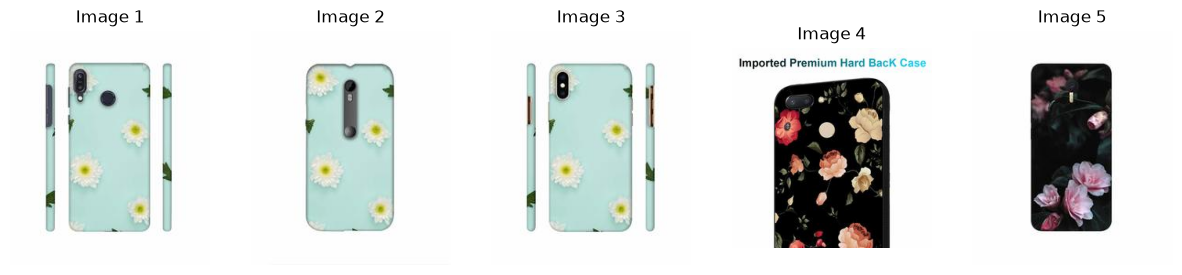

In [9]:
for MAX_IMAGES in [1_000, 10_000, 50_000]:
    Base.metadata.drop_all(engine)
    Base.metadata.create_all(engine)
    vectorize_images(engine, model, image_paths)
    for query in queries:
        print(f"MAX_IMAGES={MAX_IMAGES}, query: {query}")
        search(query, 5)

Are results relevant?

> Mostly yes. The model gets the object type and color right. Most misses happen with small datasets.

Do you see more accurate results for larger datasets?

> Yes. With 1000 images it's just some random textures. When we have 10000 images, we can see that it gets better, tables are wooden, sofas are blue, the only issue is still with shoes. And then when we have 50000, all 4 queries return relevant images.